In [2]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# BMI Prediction Capstone (standard supervised learning workflow)
# Steps: load -> EDA -> preprocess -> split -> train -> evaluate -> tune -> interpret

In [3]:
pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 4.2 MB/s  0:00:02eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [25]:
# importing the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score

In [26]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [27]:
DATA_PATH = "human_physical_attributes.csv"
TARGET = "BMI"
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [28]:
# 1. Load the dataset
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!", "Shape:", df.shape)
print(df.head())
print("\nDataset Info:", df.info())
print("\nStatistical Summary:", df.describe()) # count, mean, std, min, quartiles (50% = median), max
print("\nMissing Values:", df.isnull().sum())
print("\nUnique Counts:", df.nunique())
print("\nData Types:", df.dtypes)
print("\nDuplicates:", df.duplicated().sum())

# This dataset has no missing values. If it did, we could use:
# df = df.dropna()   or   df = df.fillna(df.median())


Dataset loaded successfully! Shape: (5000, 11)
    Height_cm  Weight_kg  Shoe_Size  Age  Exercise_Hours_Per_Week  \
0  174.967142  63.643605  39.964516   25                 4.044928   
1  168.617357  63.198788  41.083502   64                 2.296236   
2  176.476885  43.065352  40.207857   64                 2.803829   
3  185.230299  65.048647  42.331254   54                 4.866642   
4  167.658466  80.992436  45.591536   51                 0.467608   

   Daily_Calorie_Intake  Steps_Per_Day  Body_Fat_Percentage  \
0           1505.322066   12906.757997            15.844663   
1           1933.684544    6612.407630            28.051935   
2           2749.559324    5772.240208            15.281028   
3           2836.726554    8636.873964            16.096196   
4           3064.668396    7190.074803            23.390830   

   Water_Intake_Liters  Sleep_Hours_Per_Night        BMI  
0             3.805159               8.608253  22.540625  
1             2.301089              10.02

In [30]:
# Check for duplicates
duplicates = df.duplicated().sum()
if duplicates > 0:
    print(f"Found {duplicates} duplicate rows. Removing duplicates.")
    df = df.drop_duplicates()

In [31]:
#2. Summary statistics
df.select_dtypes(include=[np.number]).median()

Height_cm                   170.134656
Weight_kg                    69.738242
Shoe_Size                    42.029752
Age                          41.000000
Exercise_Hours_Per_Week       2.989904
Daily_Calorie_Intake       2503.623048
Steps_Per_Day              8022.822685
Body_Fat_Percentage          19.887625
Water_Intake_Liters           2.516599
Sleep_Hours_Per_Night         6.980269
BMI                          24.125155
dtype: float64

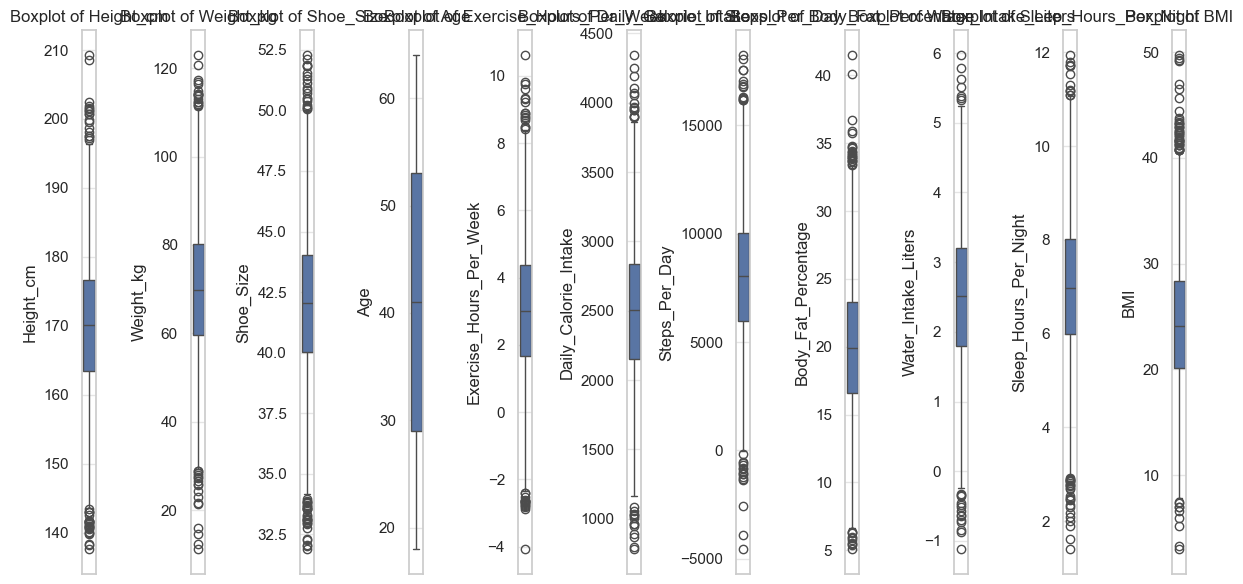

In [32]:
# Check for outliers using boxplots
plt.figure(figsize=(12, 6))
for i, column in enumerate(df.select_dtypes(include=[np.number]).columns):
    plt.subplot(1, len(df.select_dtypes(include=[np.number]).columns), i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot of {column}')
plt.tight_layout()
plt.show()

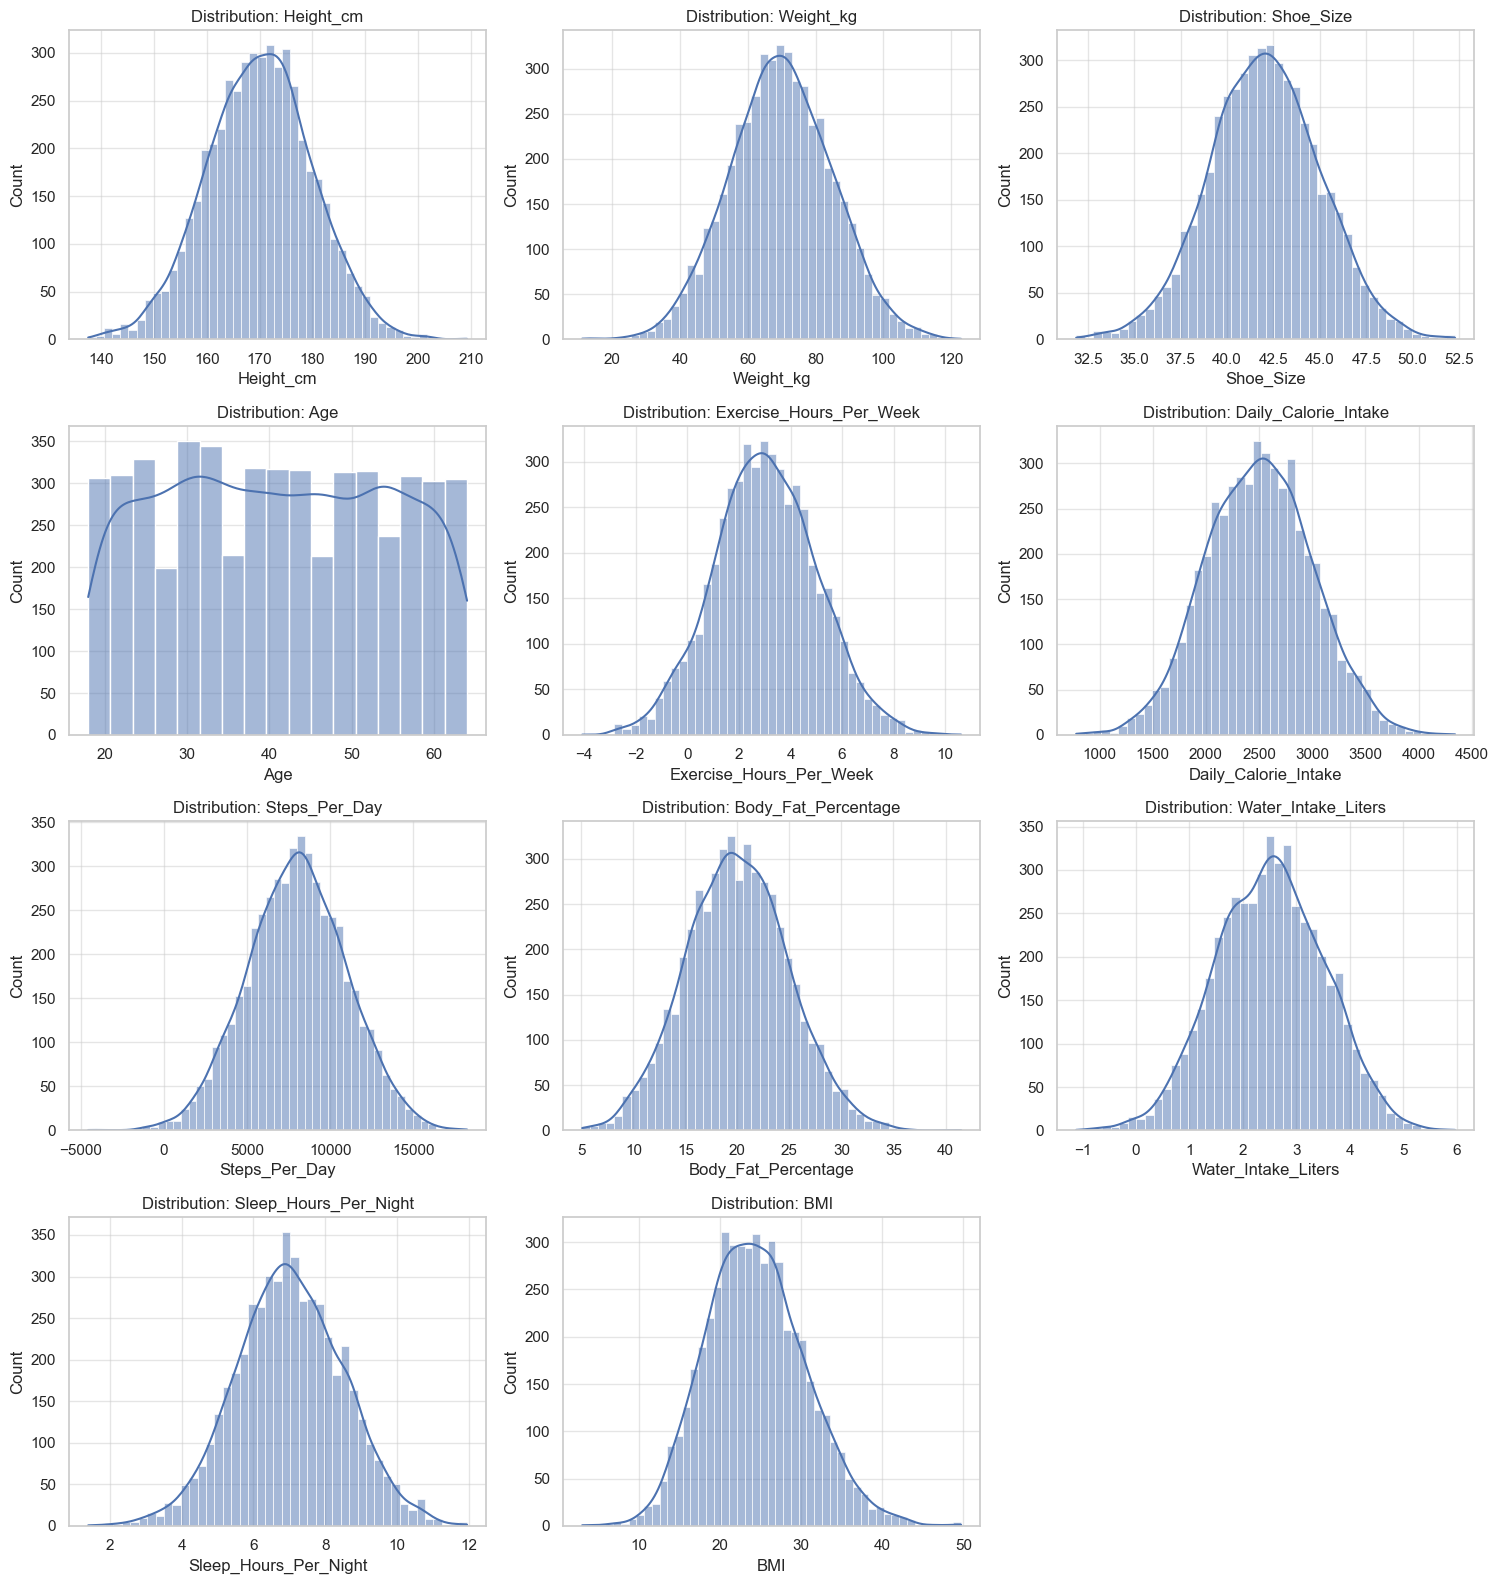

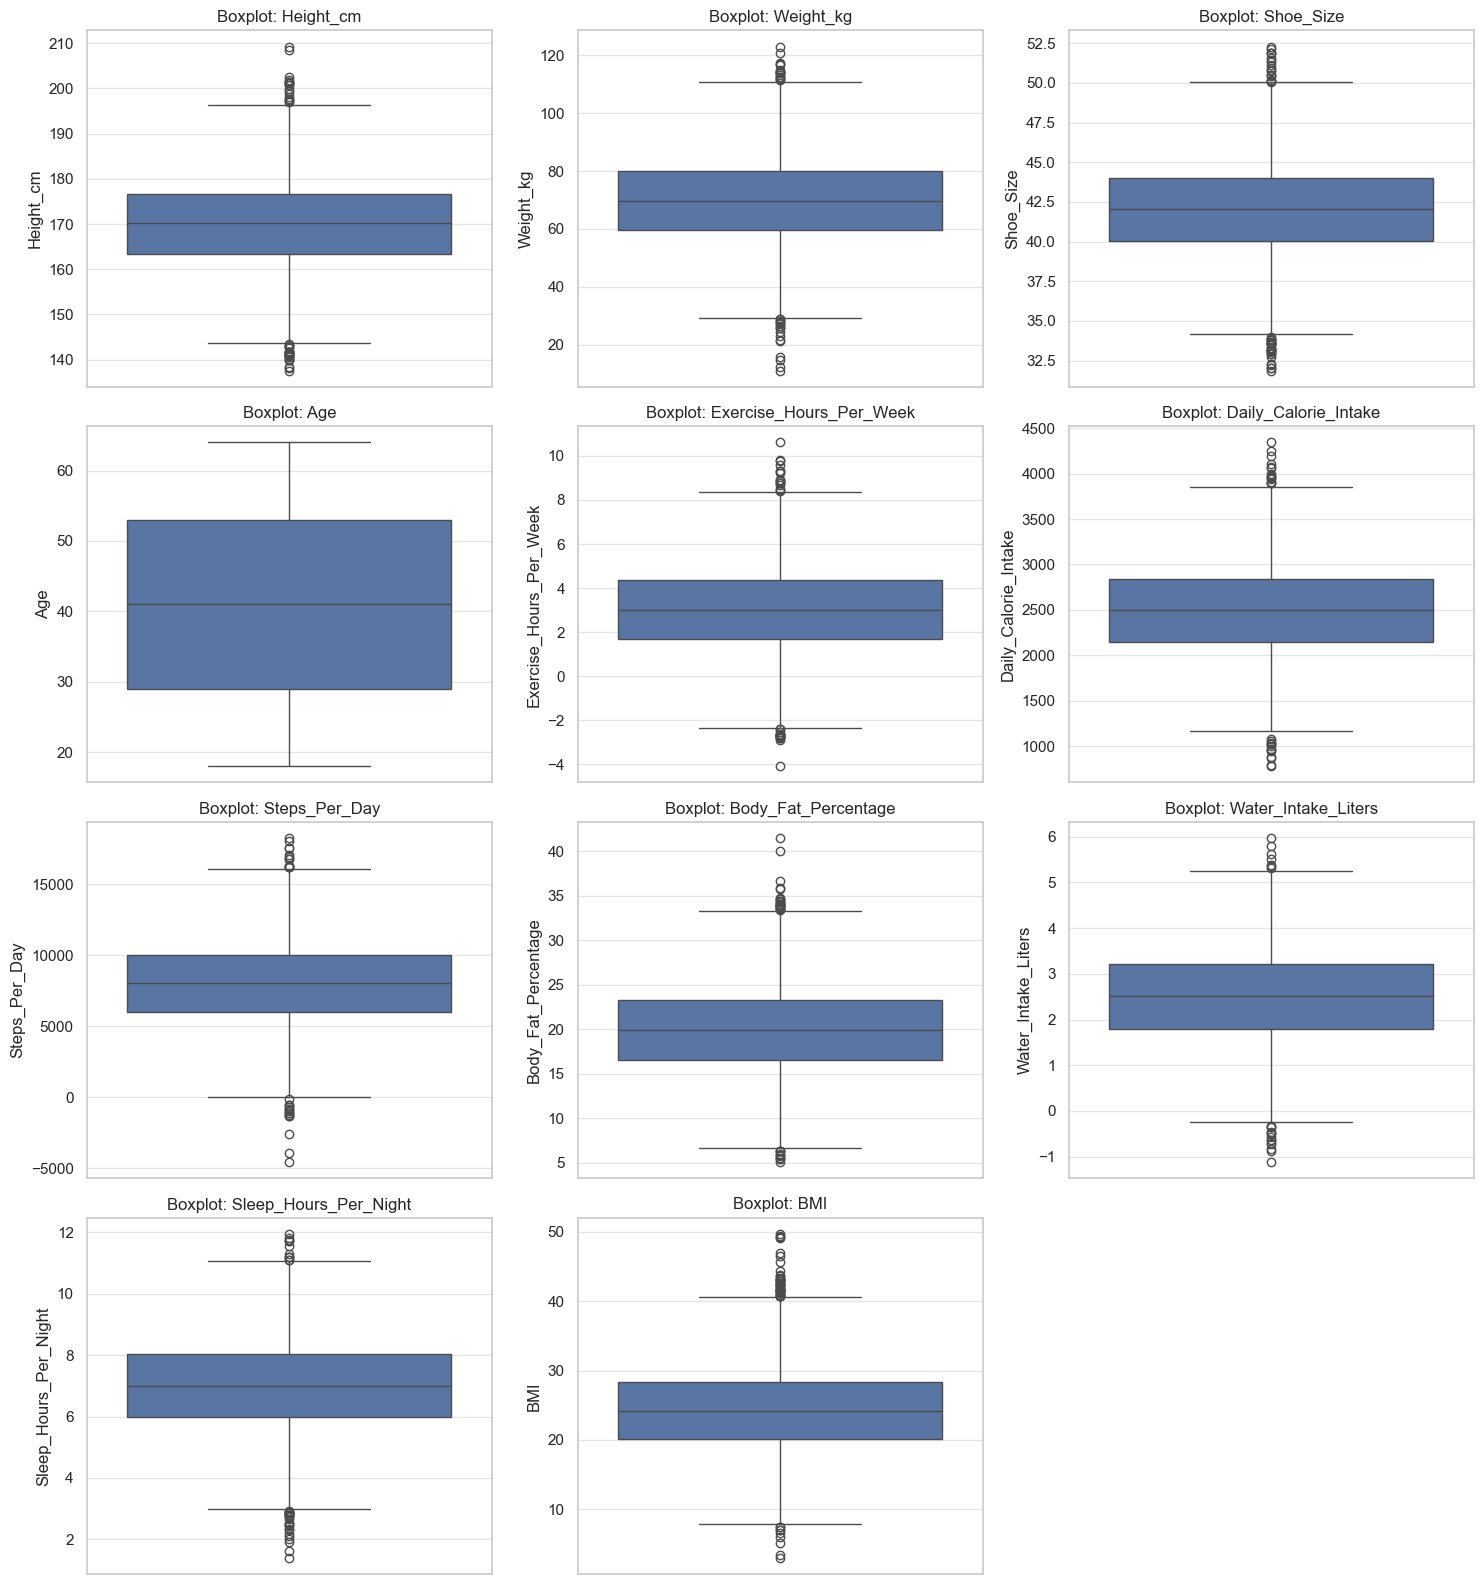

In [33]:
# 3. Distribution: histograms + boxplots
num_all = df.select_dtypes("number").columns
n = len(num_all)

fig, axes = plt.subplots(int(np.ceil(n / 3)), 3, figsize=(15, 4 * np.ceil(n / 3)))
for ax, col in zip(axes.ravel(), num_all):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(int(np.ceil(n / 3)), 3, figsize=(15, 4 * np.ceil(n / 3)))
for ax, col in zip(axes.ravel(), num_all):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot: {col}")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

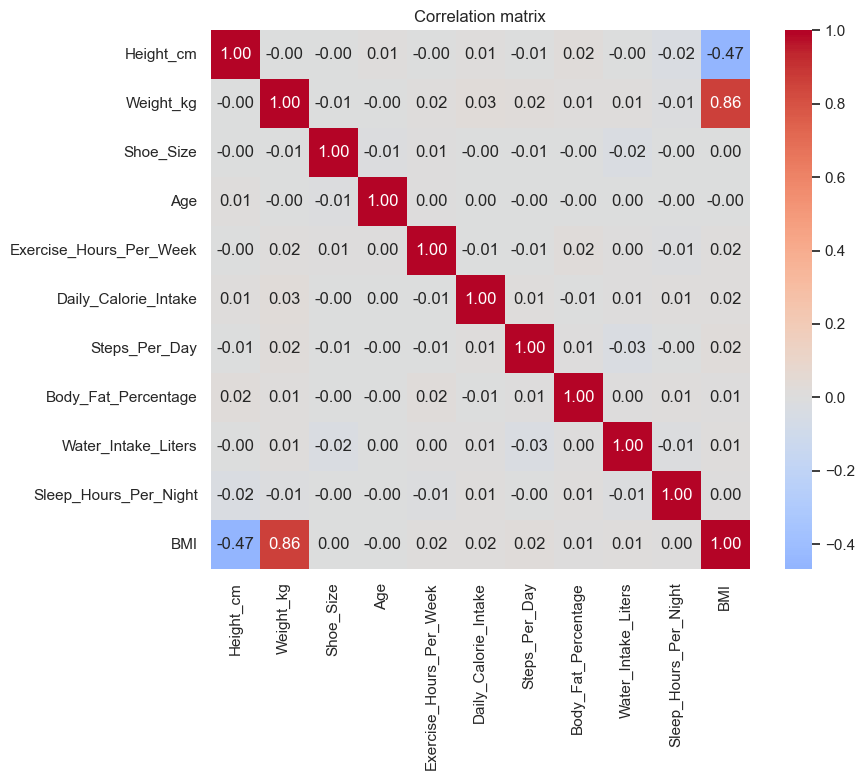

Weight_kg                  0.860893
Height_cm                 -0.468524
Steps_Per_Day              0.022134
Daily_Calorie_Intake       0.019002
Exercise_Hours_Per_Week    0.016019
Water_Intake_Liters        0.013329
Body_Fat_Percentage        0.005918
Age                       -0.004530
Sleep_Hours_Per_Night      0.003168
Shoe_Size                  0.000644
Name: BMI, dtype: float64


In [35]:
# 4. Correlation heatmap
corr = df[num_all].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
#annot=True to display correlation values, fmt=".2f" for formatting, cmap for color map, center=0 to center the colormap at 0, square=True for square cells
plt.title("Correlation matrix"); plt.show()
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False))

In [56]:
# 5a: Impossible values (data-quality check)
# Exercise hours, steps and water intake cannot be negative. Count them, then set them to 0.
for col in ["Exercise_Hours_Per_Week", "Steps_Per_Day", "Water_Intake_Liters"]:
    print(f"{col}: {(df[col] < 0).sum()} negative values")
    df[col] = df[col].clip(lower=0)
# 5b: Identify and handle outliers (IQR method)
features = df.drop(columns=["BMI"]).columns

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    # This is the IQR rule. Q1 and Q3 are the 25th and 75th percentiles, and IQR is the spread of the middle half.
    # Anything below Q1 − 1.5·IQR or above Q3 + 1.5·IQR counts as an outlier. It's the same rule boxplots use for their dots.
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n_out} outliers")
    # Handle: cap the values at the bounds (keeps all rows)
    df[col] = df[col].clip(lower, upper)

Exercise_Hours_Per_Week: 329 negative values
Steps_Per_Day: 19 negative values
Water_Intake_Liters: 35 negative values
Height_cm: 0 outliers
Weight_kg: 0 outliers
Shoe_Size: 0 outliers
Age: 0 outliers
Exercise_Hours_Per_Week: 0 outliers
Daily_Calorie_Intake: 0 outliers
Steps_Per_Day: 0 outliers
Body_Fat_Percentage: 0 outliers
Water_Intake_Liters: 0 outliers
Sleep_Hours_Per_Night: 0 outliers


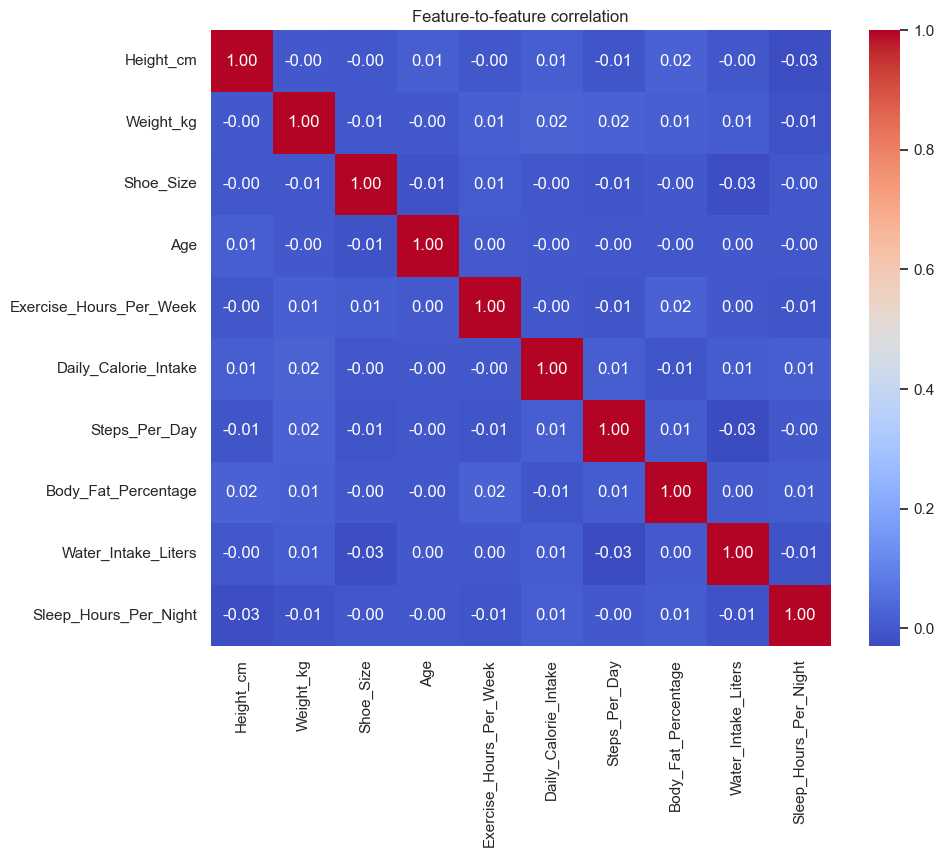

Highly correlated feature pairs: none


In [57]:
# 6. Check multicollinearity
# Simple check: correlation between the FEATURES (not the target).
# Pairs with |correlation| above ~0.8 suggest multicollinearity.
feature_corr = df[features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(feature_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature-to-feature correlation")
plt.show()

high = [(a, b, round(feature_corr.loc[a, b], 2))
        for i, a in enumerate(features) for b in features[i + 1:]
        if abs(feature_corr.loc[a, b]) > 0.8]
print("Highly correlated feature pairs:", high if high else "none")

In [40]:
# 7. Define X (features) and y (target)
X = df.drop(columns=["BMI"])
y = df["BMI"]

In [41]:
# 8. Train/test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(4000, 10) (1000, 10)


In [44]:
# 9. Standardize (fit on TRAIN only, then apply to test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

In [55]:
# 10: Model 1 - Simple Linear Regression (one feature)
# Use the feature most correlated with BMI (found in Step 4)
best_feature = df.corr()["BMI"].drop("BMI").abs().idxmax()
print("Feature used:", best_feature)
slr = LinearRegression()
slr.fit(X_train_scaled[[best_feature]], y_train)
slr_r2 = r2_score(y_test, slr.predict(X_test_scaled[[best_feature]]))
print("Simple Linear Regression R2:", round(slr_r2, 4))

Feature used: Weight_kg
Simple Linear Regression R2: 0.766


In [46]:

# 11: Model 2 - Multiple Linear Regression (all features)
mlr = LinearRegression()
mlr.fit(X_train_scaled, y_train)
mlr_r2 = r2_score(y_test, mlr.predict(X_test_scaled))
print("Multiple Linear Regression R2:", round(mlr_r2, 4))

Multiple Linear Regression R2: 0.9568


In [47]:
# 12: Models 3-5 with default settings (alpha = 1)
ridge = Ridge(alpha=1).fit(X_train_scaled, y_train)
lasso = Lasso(alpha=1).fit(X_train_scaled, y_train)
enet = ElasticNet(alpha=1, l1_ratio=0.5).fit(X_train_scaled, y_train)

ridge_r2_default = r2_score(y_test, ridge.predict(X_test_scaled))
lasso_r2_default = r2_score(y_test, lasso.predict(X_test_scaled))
enet_r2_default = r2_score(y_test, enet.predict(X_test_scaled))

print("Ridge (alpha=1) R2:", round(ridge_r2_default, 4))
print("Lasso (alpha=1) R2:", round(lasso_r2_default, 4))
print("Elastic Net (alpha=1) R2:", round(enet_r2_default, 4))

Ridge (alpha=1) R2: 0.9568
Lasso (alpha=1) R2: 0.9143
Elastic Net (alpha=1) R2: 0.8073


      alpha   Ridge   Lasso  ElasticNet
0    0.0001  0.9568  0.9568      0.9568
1    0.0010  0.9568  0.9568      0.9569
2    0.0100  0.9568  0.9569      0.9570
3    0.1000  0.9568  0.9573      0.9556
4    1.0000  0.9568  0.9143      0.8073
5   10.0000  0.9569 -0.0000      0.0132
6  100.0000  0.9571 -0.0000     -0.0000


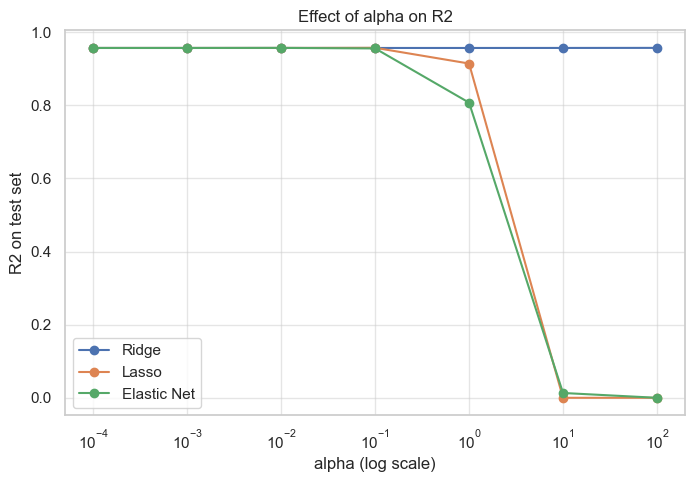

In [48]:
# 13: Hyperparameter tuning - try many alpha values
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

ridge_scores, lasso_scores, enet_scores = [], [], []

for a in alphas:
    ridge_scores.append(r2_score(y_test, Ridge(alpha=a).fit(X_train_scaled, y_train).predict(X_test_scaled)))
    lasso_scores.append(r2_score(y_test, Lasso(alpha=a).fit(X_train_scaled, y_train).predict(X_test_scaled)))
    enet_scores.append(r2_score(y_test, ElasticNet(alpha=a, l1_ratio=0.5).fit(X_train_scaled, y_train).predict(X_test_scaled)))

tuning = pd.DataFrame({"alpha": alphas, "Ridge": ridge_scores,
                       "Lasso": lasso_scores, "ElasticNet": enet_scores})
print(tuning.round(4))

plt.figure(figsize=(8, 5))
plt.semilogx(alphas, ridge_scores, marker="o", label="Ridge")
plt.semilogx(alphas, lasso_scores, marker="o", label="Lasso")
plt.semilogx(alphas, enet_scores, marker="o", label="Elastic Net")
plt.xlabel("alpha (log scale)")
plt.ylabel("R2 on test set")
plt.title("Effect of alpha on R2")
plt.legend()
plt.show()

In [49]:
# 14: Pick the best alpha for each model and refit
best_ridge_alpha = alphas[int(np.argmax(ridge_scores))]
best_lasso_alpha = alphas[int(np.argmax(lasso_scores))]
best_enet_alpha = alphas[int(np.argmax(enet_scores))]
print("Best alphas:", best_ridge_alpha, best_lasso_alpha, best_enet_alpha)

ridge_best = Ridge(alpha=best_ridge_alpha).fit(X_train_scaled, y_train)
lasso_best = Lasso(alpha=best_lasso_alpha).fit(X_train_scaled, y_train)
enet_best = ElasticNet(alpha=best_enet_alpha, l1_ratio=0.5).fit(X_train_scaled, y_train)

Best alphas: 100 0.1 0.01


                 Model      R2
3        Lasso (tuned)  0.9573
2        Ridge (tuned)  0.9571
4  Elastic Net (tuned)  0.9570
1          Multiple LR  0.9568
0            Simple LR  0.7660


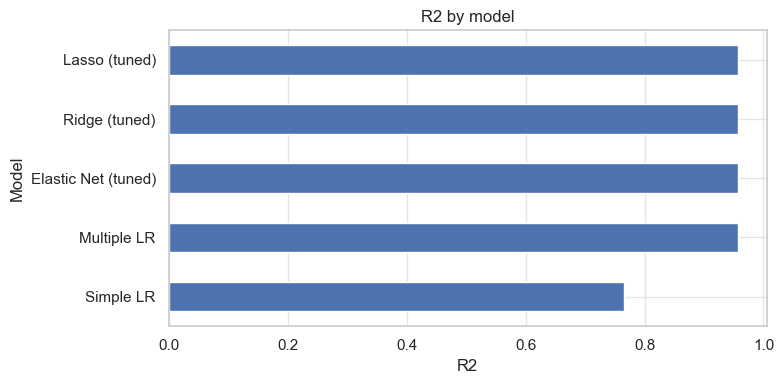

In [50]:
# 15: Compare all models
results = pd.DataFrame({
    "Model": ["Simple LR", "Multiple LR", "Ridge (tuned)", "Lasso (tuned)", "Elastic Net (tuned)"],
    "R2": [slr_r2, mlr_r2,
           r2_score(y_test, ridge_best.predict(X_test_scaled)),
           r2_score(y_test, lasso_best.predict(X_test_scaled)),
           r2_score(y_test, enet_best.predict(X_test_scaled))],
}).sort_values("R2", ascending=False)
print(results.round(4))

results.set_index("Model")["R2"].sort_values().plot(kind="barh", figsize=(8, 4), title="R2 by model")
plt.xlabel("R2")
plt.tight_layout()
plt.show()

Best model: Lasso (tuned)
Weight_kg                  5.1604
Height_cm                 -2.8160
Shoe_Size                  0.0000
Age                       -0.0000
Exercise_Hours_Per_Week    0.0000
Daily_Calorie_Intake       0.0000
Steps_Per_Day             -0.0000
Body_Fat_Percentage        0.0000
Water_Intake_Liters        0.0000
Sleep_Hours_Per_Night      0.0000
dtype: float64

Change in BMI per 1 raw unit:
 Height_cm                 -0.2831
Weight_kg                  0.3442
Shoe_Size                  0.0000
Age                       -0.0000
Exercise_Hours_Per_Week    0.0000
Daily_Calorie_Intake       0.0000
Steps_Per_Day             -0.0000
Body_Fat_Percentage        0.0000
Water_Intake_Liters        0.0000
Sleep_Hours_Per_Night      0.0000
dtype: float64


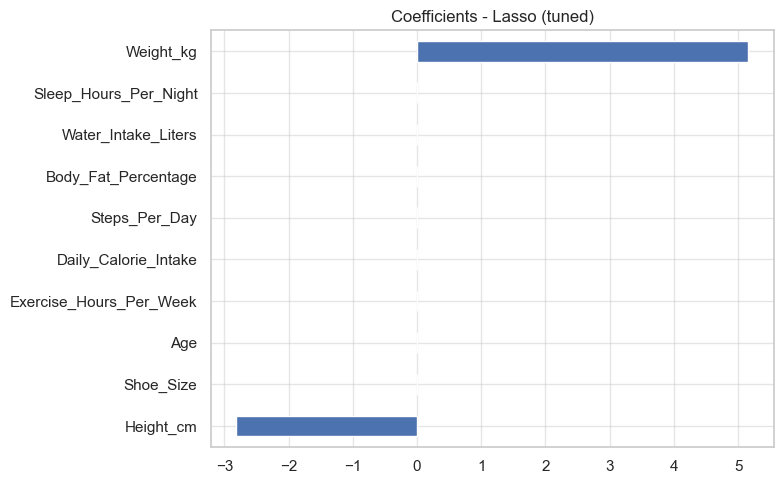


Features removed by Lasso: ['Shoe_Size', 'Age', 'Exercise_Hours_Per_Week', 'Daily_Calorie_Intake', 'Steps_Per_Day', 'Body_Fat_Percentage', 'Water_Intake_Liters', 'Sleep_Hours_Per_Night']


In [53]:
 # 16: Interpret the coefficients of the best model
models = {"Simple LR": slr, "Multiple LR": mlr, "Ridge (tuned)": ridge_best,
          "Lasso (tuned)": lasso_best, "Elastic Net (tuned)": enet_best}
best_name = results.iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

coefs = pd.Series(best_model.coef_, index=X.columns)
print(coefs.sort_values(key=abs, ascending=False).round(4))

# Because we standardized, each coefficient = change in BMI for a +1 std increase in that feature.
# Divide by the feature's std to get the change per 1 raw unit (per kg, per cm, ...).
per_unit = coefs / scaler.scale_
print("\nChange in BMI per 1 raw unit:\n", per_unit.round(4))

coefs.sort_values().plot(kind="barh", figsize=(8, 5), title=f"Coefficients - {best_name}")
plt.tight_layout()
plt.show()


# Features Lasso / Elastic Net set to exactly 0 were "dropped" by feature selection
print("\nFeatures removed by Lasso:", list(X.columns[lasso_best.coef_ == 0]))

                 Model  R2_train  R2_test  RMSE_test
0            Simple LR    0.7337   0.7660     2.9388
1          Multiple LR    0.9583   0.9568     1.2624
2        Ridge (tuned)    0.9577   0.9571     1.2586
3        Lasso (tuned)    0.9577   0.9573     1.2557
4  Elastic Net (tuned)    0.9582   0.9570     1.2595


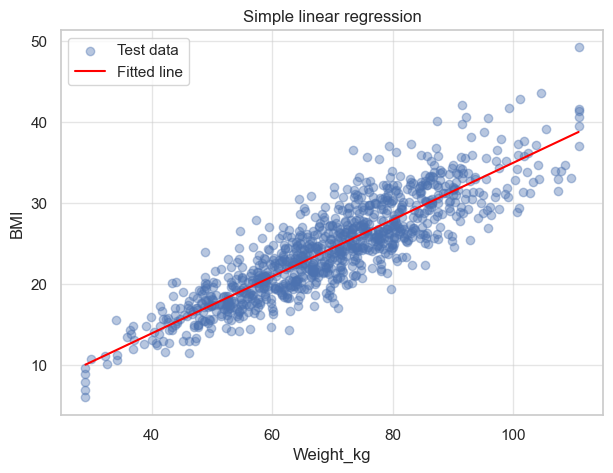

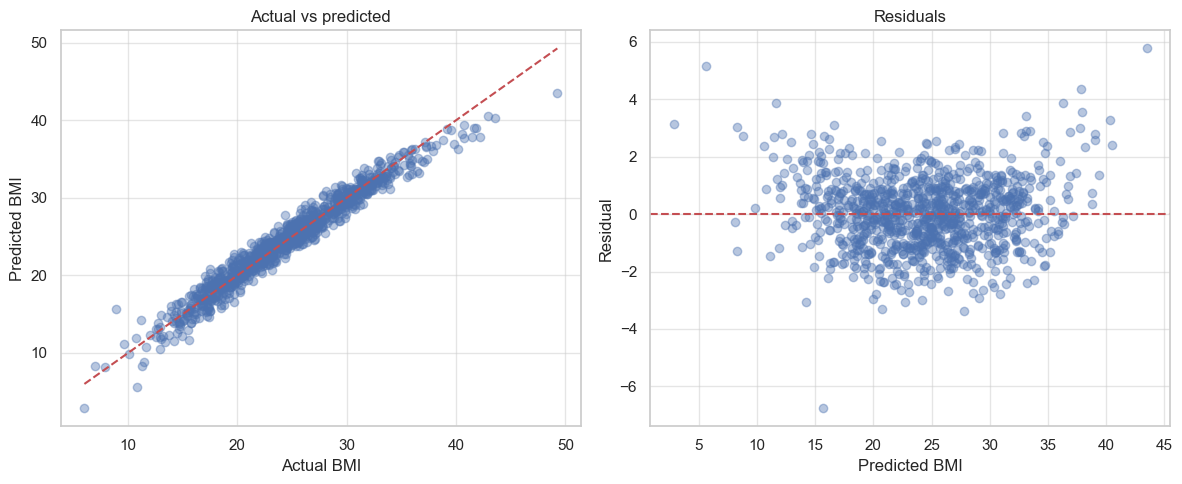

In [58]:
# 17: Extra diagnostics for the report
# (a) Train vs test R2 and RMSE - checks for overfitting and gives error in BMI units
from sklearn.metrics import mean_squared_error
rows = []
for name, m in models.items():
    if name == "Simple LR":
        Xtr, Xte = X_train_scaled[[best_feature]], X_test_scaled[[best_feature]]
    else:
        Xtr, Xte = X_train_scaled, X_test_scaled
    rows.append([name,
                 r2_score(y_train, m.predict(Xtr)),
                 r2_score(y_test, m.predict(Xte)),
                 np.sqrt(mean_squared_error(y_test, m.predict(Xte)))])
diag = pd.DataFrame(rows, columns=["Model", "R2_train", "R2_test", "RMSE_test"])
print(diag.round(4))

# (b) Simple linear regression: the fitted line on the test data
plt.figure(figsize=(7, 5))
plt.scatter(X_test[best_feature], y_test, alpha=0.4, label="Test data")
xs = np.linspace(X_test[best_feature].min(), X_test[best_feature].max(), 100)
xs_scaled = (xs - scaler.mean_[list(X.columns).index(best_feature)]) / scaler.scale_[list(X.columns).index(best_feature)]
plt.plot(xs, slr.predict(pd.DataFrame({best_feature: xs_scaled})), color="red", label="Fitted line")
plt.xlabel(best_feature); plt.ylabel("BMI"); plt.title("Simple linear regression")
plt.legend(); plt.show()

# (c) Actual vs predicted and residuals for the best model
pred = best_model.predict(X_test_scaled)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(y_test, pred, alpha=0.4)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ax[0].set_xlabel("Actual BMI"); ax[0].set_ylabel("Predicted BMI"); ax[0].set_title("Actual vs predicted")
ax[1].scatter(pred, y_test - pred, alpha=0.4)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted BMI"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()